# 07 · Can early claim counts estimate an event’s eventual size?
**Venkat Repaka and Ritik Gaire · NFIP flood claims**

**Question:** can the number of claims opened in the first days of a storm tell us the final number of claims?

We compare a simple rule with a regression, test on later storms only, and check how sensitive the answer is to the storm's start date.

**Learning bridge:** notebook 05 raised a capacity hypothesis without proving it. Here we test whether early counts add useful planning information. We move from a promising correlation to serious baselines, event tests, chronological tests and a timing sensitivity check.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from project_utils import *
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df=load_joined()

### Step 1 · Build one event row and define the clock
The earliest loss is an approximation to an event start. We retain that limitation before seeing the prediction results.

In [2]:
s=df[df.floodEvent.notna()].copy()
# Earliest recorded loss replaces the previous full-event modal date.
# It can still be revised later; this is an approximation to an operational start.
starts=s.groupby('floodEvent').dateOfLoss.min()
s['day']=(s.openDate-s.floodEvent.map(starts)).dt.days
z=s.groupby('floodEvent').agg(total=('id','size'),total_paid=('amountPaidOnBuildingClaim','sum'))
z['start']=starts
for n in [3,7,14,30]:
    z[f'day{n}']=s[s.day.between(0,n)].groupby('floodEvent').size()
z=z.fillna(0)
z=z[(z.total>=300)&(z.start<'2025-01-01')].sort_values('start')
print(f'Events: {len(z)}; events above 20,000 claims: {z.total.gt(20000).sum()}')
print('Negative days excluded from early counts:',s.day.lt(0).sum())
display(z.tail(10))

Events: 34; events above 20,000 claims: 4
Negative days excluded from early counts: 9


,total,total_paid,start,day3,day7,day14,day30
floodEvent,,,,,,,
December Nor'easter,1968,"51,360,974.080",2023-12-16,976.000,"1,497.000",1687,1827
Texas Spring Flooding,1054,"62,841,246.180",2024-04-18,0.000,1.000,262,965
June South Florida Flooding,1478,"83,379,377.210",2024-06-11,714.000,"1,047.000",1270,1381
June Midwest Flooding,347,"19,818,362.430",2024-06-20,17.000,280.000,319,330
Hurricane Beryl,2528,"51,824,798.360",2024-07-07,934.000,"1,281.000",1772,2167
Hurricane Debby,2436,"93,141,200.270",2024-08-03,827.000,"1,495.000",2048,2257
Hurricane Francine,2095,"81,825,891.410",2024-09-09,898.000,"1,538.000",1819,1977
Tropical Cyclone Eight,738,"25,845,716.550",2024-09-15,464.000,568.000,635,685
Hurricane Helene,58090,"5,923,713,194.150",2024-09-24,"18,918.000","43,853.000",51868,55265


## 1. Timing and sample limits
We define day zero as the earliest recorded loss for the named event. Unlike a modal date, this does not require counting all later claims, but the start can still be revised and one bad early date can move it. Operational testing would need historical event announcements and arrival records as they were known then.

Counts include day zero through the stated day. We restrict events to 2020–2024 to allow more reporting time and at least 300 recorded claims for a stable comparison. This outcome-based size filter limits the result to established events; it does not evaluate false warnings across every small flood.

,median % reported
day 3,41.000
day 7,70.900
day 14,83.900
day 30,92.800


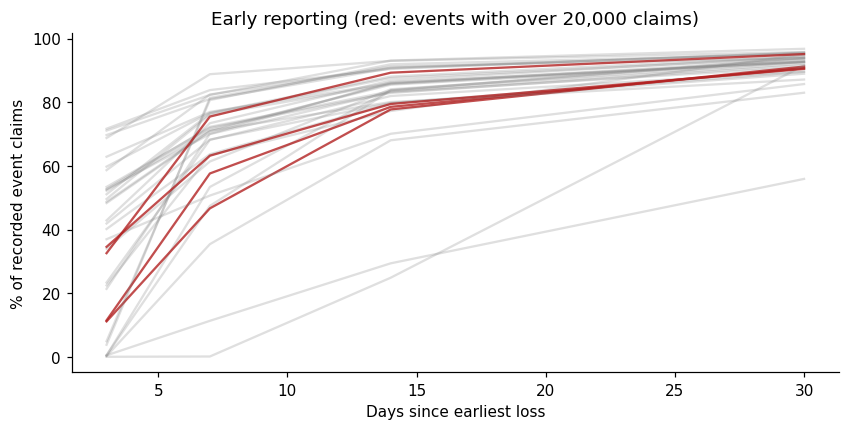

In [3]:
shares=pd.DataFrame({f'day {n}':z[f'day{n}']/z.total for n in [3,7,14,30]})
display(shares.median().mul(100).round(1).to_frame('median % reported'))
fig,ax=plt.subplots(figsize=(9,4))
for name,g in shares.iterrows():
    ax.plot([3,7,14,30],g*100,color='firebrick' if z.loc[name,'total']>20000 else 'gray',alpha=.8 if z.loc[name,'total']>20000 else .25)
ax.set(xlabel='Days since earliest loss',ylabel='% of recorded event claims',title='Early reporting (red: events with over 20,000 claims)');plt.show()

### Step 2 · The correlation looks promising; is that enough?
Early counts are part of the total, so a high relationship is partly expected. We show it, then move to prediction errors and a baseline that uses the same early information.

Correlation of log early counts with log recorded total: 0.795


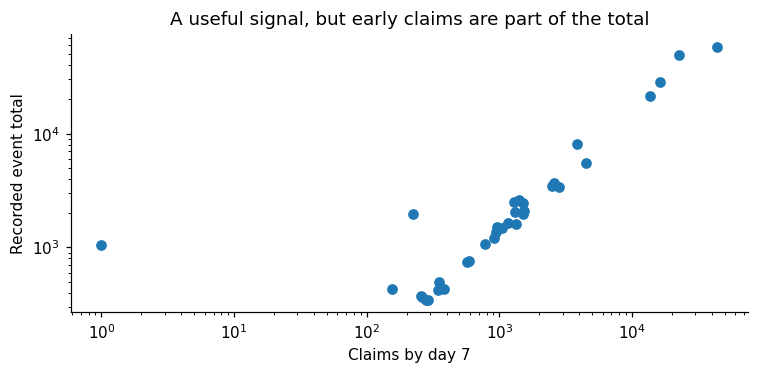

In [4]:
print('Correlation of log early counts with log recorded total:',round(np.log1p(z.day7).corr(np.log1p(z.total)),3))
plt.figure(figsize=(7,3.5));plt.scatter(z.day7,z.total);plt.xscale('log');plt.yscale('log');plt.xlabel('Claims by day 7');plt.ylabel('Recorded event total');plt.title('A useful signal, but early claims are part of the total');plt.tight_layout();plt.show()

## 2. Four methods with the same information

| Method | Prediction |
|---|---|
| Median event | Median recorded total in fitting events |
| Observed count | Claims already opened; no growth adjustment |
| Completion factor | Early count ÷ median share reported by this day in fitting events |
| Log-linear regression | A fitted relationship between log early count and log event total |

The completion factor is a serious baseline: it uses the same early count as the regression. A high correlation between early and total counts is expected because early claims are part of the total. We therefore judge **prediction error**, not correlation alone.

### Step 3 · Define all four rules before comparing errors
The completion-factor rule uses a historical reporting fraction and is a serious alternative to regression.

In [5]:
from sklearn.linear_model import LinearRegression

def predict_count(training,held,n,method):
    early=held[f'day{n}'].to_numpy(float)
    if method=='median event': return np.full(len(held),training.total.median())
    if method=='observed count': return early
    if method=='completion factor':
        fraction=(training[f'day{n}']/training.total).median()
        return early/max(fraction,1e-6)
    m=LinearRegression().fit(np.log1p(training[[f'day{n}']]),np.log1p(training.total))
    return np.maximum(np.expm1(m.predict(np.log1p(held[[f'day{n}']]))),early)

### Step 4 · Leave one event out
This tests excluded events but can still fit on later events. It is not yet a historical forecast.

In [6]:
methods=['median event','observed count','completion factor','log-linear regression']
records=[]
for n in [3,7,14]:
    for name in z.index:
        training=z.drop(name);held=z.loc[[name]]
        for method in methods:
            p=predict_count(training,held,n,method)[0]
            records.append({'event':name,'day':n,'method':method,'actual':held.total.iloc[0],'prediction':p,
                            'absolute % error':abs(p/held.total.iloc[0]-1)*100})
loo=pd.DataFrame(records)
summary=loo.groupby(['day','method'])['absolute % error'].agg(median='median',mean='mean',worst='max')
display(summary.round(2));save_table(summary,'07_leave_event_out')

median    mean   worst
day method                                       
3   completion factor      46.230  50.470 100.000
    log-linear regression  73.510 103.970 417.270
    median event           55.180 110.800 369.650
    observed count         58.980  63.700 100.000
7   completion factor      10.880  17.550  99.870
    log-linear regression  38.440  55.170 161.050
    median event           55.180 110.800 369.650
    observed count         29.070  34.600  99.910
14  completion factor       5.180   9.370  70.430
    log-linear regression  11.090  14.460  68.850
    median event           55.180 110.800 369.650
    observed count         16.070  19.100  75.140

## 3. Chronological evaluation
Leaving one event out can train on future events. We now fit on events before 2024 and evaluate 2024 events. We report every method without selecting a winner using 2024 outcomes. The number of large events is small, so the differences may change in another year.

### Step 5 · Now respect time
Only earlier events provide the completion fraction or fitted line.

In [7]:
training=z[z.start<'2024-01-01'];held=z[z.start>='2024-01-01']
chron=[]
for n in [3,7,14]:
    for method in methods:
        pp=predict_count(training,held,n,method)
        for name,a,p in zip(held.index,held.total,pp):
            chron.append({'event':name,'day':n,'method':method,'actual':a,'prediction':p,'absolute % error':abs(p/a-1)*100})
chron=pd.DataFrame(chron)
display(chron.groupby(['day','method'])['absolute % error'].agg(['median','mean','max']).round(2))
save_table(chron,'07_chronological_predictions')

median   mean     max
day method                                      
3   completion factor      29.110 38.750 100.000
    log-linear regression  65.450 59.710 161.430
    median event           52.850 91.940 364.270
    observed count         65.450 67.000 100.000
7   completion factor      11.010 20.560  99.870
    log-linear regression  14.750 24.900  99.710
    median event           52.850 91.940 364.270
    observed count         29.160 38.580  99.910
14  completion factor       5.080 13.080  70.300
    log-linear regression   7.220 14.890  68.340
    median event           52.850 91.940 364.270
    observed count         14.070 22.390  75.140

### Step 6 · Counts and warnings are different outcomes
An accurate count can still miss a threshold by a small amount. We report both the count errors and warning counts.

In [8]:
warning=chron.copy();warning['actual_large']=warning.actual>20000;warning['warned']=warning.prediction>20000
warn=warning.groupby(['day','method']).apply(lambda g:pd.Series({'large events':g.actual_large.sum(),
    'large events warned':(g.actual_large & g.warned).sum(),'false warnings':(~g.actual_large & g.warned).sum()}),include_groups=False)
display(warn)

large events  large events warned  false warnings
day method                                                                  
3   completion factor                 2                    1               0
    log-linear regression             2                    0               0
    median event                      2                    0               0
    observed count                    2                    0               0
7   completion factor                 2                    1               0
    log-linear regression             2                    1               0
    median event                      2                    0               0
    observed count                    2                    1               0
14  completion factor                 2                    2               0
    log-linear regression             2                    2               0
    median event                      2                    0               0
    observed count                    2                    1               0

### Step 6a · Repeat the test for more than one year
One test year has very few storms. We now repeat the chronological test for 2022, 2023 and 2024. Each time, we learn only from storms that started before that year. This gives more storms to judge, though the numbers are still small.

In [9]:
roll=[]
for year in [2022,2023,2024]:
    earlier=z[z.start<f'{year}-01-01'];later=z[(z.start>=f'{year}-01-01')&(z.start<f'{year+1}-01-01')]
    if len(later)==0 or len(earlier)<5:continue
    for n in [3,7,14]:
        for method in methods:
            pp=predict_count(earlier,later,n,method)
            roll.append({'test year':year,'day':n,'method':method,'storms tested':len(later),
                         'median abs % error':np.median(np.abs(pp/later.total.to_numpy()-1))*100})
rolling=pd.DataFrame(roll)
display(rolling.pivot_table(index=['day','method'],columns='test year',values='median abs % error').round(1))
save_table(rolling,'07_rolling_origin')

test year                   2022   2023   2024
day method                                    
3   completion factor     62.900 84.800 29.100
    log-linear regression 59.400 31.600 65.400
    median event          30.800 58.000 52.800
    observed count        70.100 41.300 65.400
7   completion factor     21.600 10.900 11.000
    log-linear regression 20.100 29.700 14.700
    median event          30.800 58.000 52.800
    observed count        41.200 23.300 29.200
14  completion factor      5.900  5.700  5.100
    log-linear regression  5.200 12.400  7.200
    median event          30.800 58.000 52.800
    observed count        21.100 11.900 14.100

## 4. Sensitivity to the event start date
A very early loss can shift day zero before most flooding began. We show the gap between the earliest and most common loss date. We also repeat the chronological comparison using the most common date. That date uses the full event record, so it is a **hindsight sensitivity check**, not a usable first-day forecast.

If scores change strongly, the timing definition is a major source of uncertainty. We keep the earlier chronological test as the primary result.

In [10]:
modal=s.groupby('floodEvent').dateOfLoss.agg(lambda v:v.mode().iloc[0])
gap=(modal-starts).dt.days.loc[z.index].sort_values(ascending=False)
display(gap.head(8).to_frame('days from earliest to modal loss'))
modal_day=(s.openDate-s.floodEvent.map(modal)).dt.days
zm=z.copy()
for day in [3,7,14]:
    zm[f'day{day}']=s[modal_day.between(0,day)].groupby('floodEvent').size().reindex(zm.index,fill_value=0)
rows=[]
for day in [3,7,14]:
    for method in ['completion factor','log-linear regression']:
        a=zm[zm.start<'2024-01-01'];b=zm[zm.start>='2024-01-01']
        pp=predict_count(a,b,day,method)
        rows.append({'day':day,'method':method,'hindsight modal-start median error %':np.median(np.abs(pp/b.total.to_numpy()-1))*100})
display(pd.DataFrame(rows).set_index(['day','method']).round(2))


,days from earliest to modal loss
floodEvent,
Texas Spring Flooding,14
California Atmospheric River,13
Hurricane Isaias,6
Hurricane Sally,5
Texas Severe Winter Storms,5
Hurricane Elsa,4
Hurricane Eta,4
Tropical Storm Fred,4


hindsight modal-start median error %
day method                                                     
3   completion factor                                    14.890
    log-linear regression                                13.130
7   completion factor                                     9.360
    log-linear regression                                14.400
14  completion factor                                     7.670
    log-linear regression                                 9.000

## 5. Answer and limits
**Answer.** After one week, the simple completion rule (early count divided by the usual share reported by that day) is the better guide to the final number of claims. It beats the regression in most test years. By day 3 both are poor, because only about 40% of claims have arrived.

**What we cannot say.** A 20,000-claim alert is only a size label. Notebook 05 did not show that 20,000 claims causes a staffing problem. We tested few large storms, event names and start dates are revised later, and we have no timestamps of when claims actually arrived. Zero false alarms in a small sample does not show the alert is reliable.

**What a real test needs.** Start dates fixed in advance, every storm (including small ones), and only the records that were known at each warning time.

### Decision ledger
We kept early counts as useful information, discarded correlation alone as proof, and compared regression with a completion rule. We kept chronological testing and the date-definition sensitivity check. We did not claim that the 20,000-claim alert predicts a proven staffing failure or that zero false warnings in a small selected sample proves future reliability.

### Result in plain English

On the chronological 2024 evaluation, the day-seven completion-factor rule has median absolute error **11.0%**, compared with **14.7%** for regression. The simple rule is the stronger benchmark in this comparison. The start-date sensitivity check is essential: a very early loss record can move the warning window. A high early-count correlation alone is not enough, because the early claims are already part of the total. The small event sample and revised dates prevent a strong claim about operational warning reliability.